# Assignment: Build, Inspect, and Optimize a CNN on CIFAR-10

**Topic:** Convolutional Neural Networks  
**Platform:** Google Colab (GPU runtime recommended)  
**Dataset:** CIFAR-10  


## Learning objectives

By the end of this assignment, you should be able to:

1. Load, inspect, preprocess, and visualize CIFAR-10.
2. Design and train a convolutional neural network (CNN) for 10-class image classification.
3. Explain what intermediate CNN feature maps show and inspect activations from selected layers.
4. Implement a **configurable CNN**, where architecture choices are controlled by a configuration rather than hard-coded model definitions.
5. Run controlled architecture experiments and keep a reproducible experiment log.
6. Evaluate a multiclass classifier using **accuracy, precision, recall, and F1-score**, in addition to inspecting training/validation curves.

## Rules for a fair experiment

- Use the provided train/validation/test split. Do not use the test set to make architecture or hyperparameter decisions.
- Use the validation set to compare configurations. Evaluate the selected final model on the test set only after experimentation is complete.
- Change a small number of design choices at a time and record exactly what changed.
- Set random seeds and keep a record of your configuration.
- Do not claim that one model is better based on training accuracy alone. Consider validation metrics, curves, class-wise performance, and the gap between training and validation results.

> **Deliverable:** Submit this completed notebook with code, plots, a filled experiment log, metric results, intermediate-layer visualizations, and short written answers to the questions.

**Completed assignment — Sajjad Ranjbar**  
**Student ID:** 405522012  
**Program:** Computer Science, Faculty of Mathematical Sciences, Shahid Beheshti University (SBU)

The experiments below use real CIFAR-10 and a full, fixed split. This cloud
machine has CPUs only; CUDA is used automatically if available on a later run.
OpenAI Codex assisted with this implementation and report. Review the code,
measurements, and explanations before submission. API and dataset sources are
cited at the end. The experiment budget is deliberately modest, not a claim
of an optimal CIFAR-10 classifier.

## Part 0 — Runtime and imports

In Colab, select **Runtime → Change runtime type → T4 GPU** (if available). A GPU is recommended .

A single Colab session is generally sufficient for modest CNN experiments on CIFAR-10. Runtime availability and duration are not guaranteed, so save important checkpoints and experiment results to persistent storage if needed.

In [1]:
from pathlib import Path
import os, sys, json, random, time, hashlib, platform, copy, urllib.request
import numpy as np
import torch
from torch import nn
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "Noebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "Noebooks").is_dir(), "Run from the repository or Noebooks directory"
REPORT_DIR = PROJECT_ROOT / "report"
FIGURE_DIR, RESULT_DIR = REPORT_DIR / "figures", REPORT_DIR / "results"
CHECKPOINT_DIR = REPORT_DIR / "checkpoints"
for directory in (FIGURE_DIR, RESULT_DIR, CHECKPOINT_DIR):
    directory.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get("CIFAR_ROOT", str(PROJECT_ROOT / "data")))
SEED = 42
EPOCHS, BATCH_SIZE = 10, 128
LEARNING_RATE, WEIGHT_DECAY = 3e-3, 1e-4
NUM_WORKERS = 2
# Limit oversubscription on this four-core cloud instance.
torch.set_num_threads(int(os.environ.get("CNN_NUM_THREADS", "4")))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()
print("Python:", platform.python_version(), "PyTorch:", torch.__version__)
print("Device:", device, "Threads:", torch.get_num_threads())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Epochs per run:", EPOCHS, "Batch size:", BATCH_SIZE)

Python: 3.12.14 PyTorch: 2.9.1+cpu
Device: cpu Threads: 4
Epochs per run: 10 Batch size: 128


## Part 1 — Load and understand CIFAR-10

CIFAR-10 contains 60,000 colour images of size **32 × 32 × 3**, divided into 10 classes. There are 50,000 training images and 10,000 official test images. We will take a validation subset from the training data so that the test set remains untouched until the final evaluation.<br>
## important Note
brefore continuing be sure to calculate train mean and std **seperately from the test split** and normalize the images with them. transforms are left blank in the cell below so that you would compose them yourself, please at the very least construct the normalization transform.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torchvision
import sklearn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.datasets.utils import check_integrity
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
MIRROR_COMMIT = "48ece5ce490482885f7a9a492fa031c1de79519c"
MIRROR_BASE = f"https://raw.githubusercontent.com/0Colin/cifar-10-batches-py/{MIRROR_COMMIT}"
BATCH_FILES = datasets.CIFAR10.train_list + datasets.CIFAR10.test_list + [
    [datasets.CIFAR10.meta["filename"], datasets.CIFAR10.meta["md5"]]]

def ensure_cifar10(root):
    folder = root / "cifar-10-batches-py"
    if not all(check_integrity(str(folder / name), digest) for name, digest in BATCH_FILES):
        try:
            datasets.CIFAR10(root=str(root), train=True, download=True)
        except (OSError, RuntimeError) as error:
            print("Official download unavailable; using checksum-verified mirror:", type(error).__name__)
            folder.mkdir(parents=True, exist_ok=True)
            for name, digest in BATCH_FILES:
                target = folder / name
                if not check_integrity(str(target), digest):
                    temporary = target.with_suffix(".download")
                    urllib.request.urlretrieve(f"{MIRROR_BASE}/{name}", str(temporary))
                    assert check_integrity(str(temporary), digest), f"Checksum mismatch: {name}"
                    temporary.replace(target)
    # Verify all files before torchvision unpickles any mirrored data.
    assert all(check_integrity(str(folder / name), digest) for name, digest in BATCH_FILES)
    provenance = {
        "dataset": "CIFAR-10 (Krizhevsky, 2009)",
        "official_url": datasets.CIFAR10.url,
        "fallback_mirror": MIRROR_BASE,
        "note": "Original bytes verified against all torchvision CIFAR10 MD5 checksums; cached files may originate from either source.",
        "files": [{"file": name, "md5": digest,
                   "sha256": hashlib.sha256((folder / name).read_bytes()).hexdigest()}
                  for name, digest in BATCH_FILES],
    }
    (RESULT_DIR / "dataset_provenance.json").write_text(json.dumps(provenance, indent=2))
    print("Verified 7 original CIFAR-10 files before loading")

ensure_cifar10(DATA_ROOT)
raw_train = datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=False)
# Establish the split BEFORE computing preprocessing statistics.
indices = torch.randperm(len(raw_train), generator=torch.Generator().manual_seed(SEED)).tolist()
val_indices, train_indices = indices[:5000], indices[5000:]
assert len(set(train_indices) & set(val_indices)) == 0
assert len(set(train_indices) | set(val_indices)) == 50000
# Accumulate channel sums in float64 using ONLY the 45,000 training images.
channel_sum, channel_sq_sum, pixels = np.zeros(3), np.zeros(3), 0
for start in range(0, len(train_indices), 1000):
    chunk = raw_train.data[train_indices[start:start + 1000]].astype(np.float64) / 255.0
    channel_sum += chunk.sum(axis=(0, 1, 2))
    channel_sq_sum += np.square(chunk).sum(axis=(0, 1, 2))
    pixels += chunk.shape[0] * 32 * 32
MEAN = (channel_sum / pixels).tolist()
STD = np.sqrt(channel_sq_sum / pixels - np.square(MEAN)).tolist()
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
train_augmented = datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=False,
                                  transform=train_transform)
train_for_val = datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=False,
                                transform=eval_transform)
train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_for_val, val_indices)
# Delay construction of the test dataset/loader until the final selected-model evaluation.

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_train_loader():
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
                      persistent_workers=NUM_WORKERS > 0, worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(SEED))

train_loader = make_train_loader()
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
                        persistent_workers=NUM_WORKERS > 0)
preprocessing = {"seed": SEED, "train_size": len(train_dataset), "val_size": len(val_dataset),
                 "test_size": 10000, "mean": MEAN, "std": STD,
                 "statistics_source": "45,000 training images only",
                 "split_index_sha256": hashlib.sha256(np.array(indices, dtype=np.int64).tobytes()).hexdigest()}
(RESULT_DIR / "preprocessing.json").write_text(json.dumps(preprocessing, indent=2))
np.savez_compressed(RESULT_DIR / "split_indices.npz", train=train_indices, validation=val_indices)
print("Train:", len(train_dataset), "Validation:", len(val_dataset), "Reserved test:", 10000)
print("Training-only mean:", np.round(MEAN, 6), "std:", np.round(STD, 6))
label_counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "training": np.bincount(np.array(raw_train.targets)[train_indices], minlength=10),
    "validation": np.bincount(np.array(raw_train.targets)[val_indices], minlength=10)})
display(label_counts)
label_counts.to_csv(RESULT_DIR / "class_distribution.csv", index=False)

Verified 7 original CIFAR-10 files before loading


Train: 45000 Validation: 5000 Reserved test: 10000
Training-only mean: [0.49135  0.482161 0.446597] std: [0.247049 0.243554 0.261684]


,class,training,validation
0,airplane,4470,530
1,automobile,4517,483
2,bird,4522,478
3,cat,4522,478
4,deer,4507,493
5,dog,4503,497
6,frog,4483,517
7,horse,4482,518
8,ship,4489,511
9,truck,4505,495


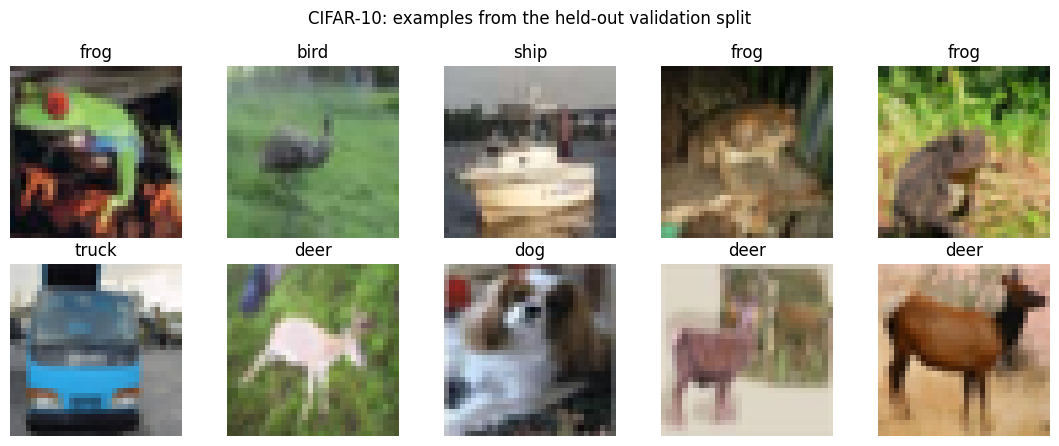

In [3]:
def denormalize(images):
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (images.detach().cpu() * std + mean).clamp(0, 1)

# Use a separate loader so visualization does not consume a training run's RNG stream.
images, labels = next(iter(DataLoader(val_dataset, batch_size=10, shuffle=False)))
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow(denormalize(image.unsqueeze(0))[0].permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[int(label)]); ax.axis("off")
fig.suptitle("CIFAR-10: examples from the held-out validation split")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "sample_images.png", dpi=150)
plt.show(); plt.close(fig)

### Questions 1

1. What is the input shape of one CIFAR-10 image as a PyTorch tensor? Why is the channel dimension in a different position from a typical image array?
2. Why do we use a validation set in addition to a training set?
3. Why should the test set not be repeatedly used to choose the architecture?
4. What does normalization do, and why might it help optimization?
5. How can normalization cause data leakage?



### Answers 1
1. One image is `(3, 32, 32)`; a batch is `(N, 3, 32, 32)`. `ToTensor`
   changes the usual image-array HWC layout to the CHW convention used by PyTorch convolutions.
2. Training fits the weights. Validation compares architectures and selects a checkpoint
   using examples that did not supply weight gradients.
3. Repeated test-based decisions indirectly fit the test set, giving an optimistic estimate.
   The official test images remain unused for model selection here.
4. Per-channel centering/scaling makes input magnitudes more comparable and can make
   gradient optimization easier. Statistics above are in the `[0, 1]` pixel scale.
5. Computing statistics with validation/test images leaks information about held-out
   inputs into preprocessing. Here the split is made first and only its 45,000
   training indices contribute to the mean and population standard deviation.

## Part 2 — Design and train your first CNN

Build a baseline CNN. Your model should accept an image batch with shape `(batch, 3, 32, 32)` and return **10 class logits** per image. Do not apply softmax in the model when using `CrossEntropyLoss`; that loss expects raw logits.

You may start with two or three convolutional blocks. A typical block is:

`Convolution → Batch Normalization (optional) → ReLU → Pooling (optional)`

The exact architecture is yours to design. Keep the baseline simple enough that you can explain every layer.

In [4]:
# Explicit baseline: three Conv -> BN -> ReLU -> MaxPool blocks.
BASELINE_CONFIG = {
    "input_channels": 3, "num_classes": 10, "activation": "relu",
    "conv_blocks": [
        {"out_channels": c, "kernel_size": 3, "stride": 1, "padding": 1,
         "batch_norm": True, "pool": 2, "conv_type": "standard"}
        for c in (16, 32, 64)],
    "classifier_hidden": 64, "dropout": 0.3}

class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2)),
            nn.Sequential(nn.Conv2d(16, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2)),
            nn.Sequential(nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)))
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64, 64), nn.ReLU(),
                                        nn.Dropout(0.3), nn.Linear(64, 10))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

probe = BaselineCNN().eval()
with torch.no_grad():
    assert probe(torch.zeros(2, 3, 32, 32)).shape == (2, 10)
print(probe)
print("Trainable parameters:", parameter_count(probe))
del probe

BaselineCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (pool): AdaptiveAvgPool

### Training and validation loop

You should record loss and accuracy after every epoch. Training accuracy is calculated on augmented training batches, so it is a useful trend rather than a perfectly comparable evaluation set. Validation metrics are computed without augmentation.

01 epoch 01/10: train loss 1.6619, val acc 0.4672, val F1 0.4462, 12.0s


01 epoch 02/10: train loss 1.3725, val acc 0.4998, val F1 0.4913, 12.1s


01 epoch 03/10: train loss 1.2503, val acc 0.5290, val F1 0.5234, 11.7s


01 epoch 04/10: train loss 1.1757, val acc 0.5866, val F1 0.5769, 11.7s


01 epoch 05/10: train loss 1.1201, val acc 0.6234, val F1 0.6200, 11.4s


01 epoch 06/10: train loss 1.0666, val acc 0.5848, val F1 0.5810, 10.8s


01 epoch 07/10: train loss 1.0286, val acc 0.6620, val F1 0.6553, 11.4s


01 epoch 08/10: train loss 0.9981, val acc 0.6654, val F1 0.6613, 11.8s


01 epoch 09/10: train loss 0.9712, val acc 0.6768, val F1 0.6716, 11.4s


01 epoch 10/10: train loss 0.9617, val acc 0.6772, val F1 0.6708, 11.8s


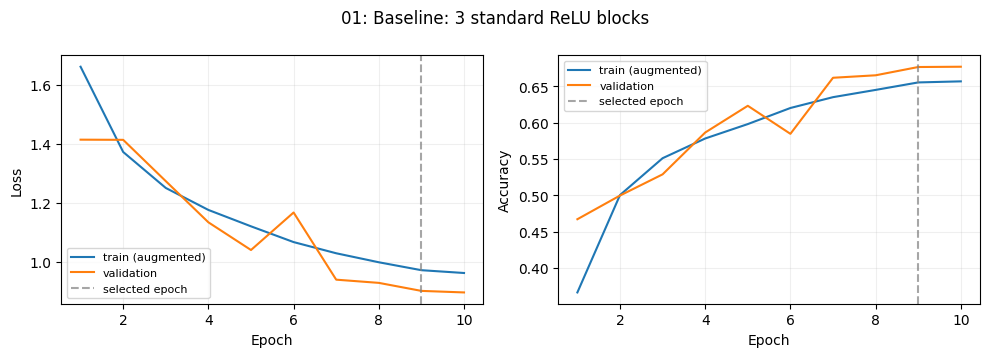

In [5]:
criterion = nn.CrossEntropyLoss()

def metric_summary(targets, predictions):
    result = {"accuracy": float(accuracy_score(targets, predictions))}
    for average in ("macro", "weighted"):
        precision, recall, f1, _ = precision_recall_fscore_support(
            targets, predictions, labels=list(range(10)), average=average, zero_division=0)
        result.update({f"{average}_precision": float(precision),
                       f"{average}_recall": float(recall), f"{average}_f1": float(f1)})
    return result

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss, targets, predictions = 0.0, [], []
    for batch, labels in loader:
        batch = batch.to(device, memory_format=torch.channels_last, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(batch)
        total_loss += criterion(logits, labels).item() * len(labels)
        targets.extend(labels.cpu().tolist())
        predictions.extend(logits.argmax(1).cpu().tolist())
    result = metric_summary(targets, predictions)
    result["loss"] = total_loss / len(targets)
    return result, np.array(targets), np.array(predictions)

def plot_history(run):
    h = pd.DataFrame(run["history"])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(h.epoch, h[f"train_{metric}"], label="train (augmented)")
        ax.plot(h.epoch, h[f"val_{metric}"], label="validation")
        ax.axvline(run["best_epoch"], ls="--", color="gray", alpha=0.7, label="selected epoch")
        ax.set(xlabel="Epoch", ylabel=metric.capitalize()); ax.legend(fontsize=8); ax.grid(alpha=0.2)
    fig.suptitle(f'{run["run_id"]}: {run["name"]}')
    fig.tight_layout(); fig.savefig(FIGURE_DIR / f'{run["run_id"]}_curves.png', dpi=150)
    plt.show(); plt.close(fig)

# Predeclared comparison rule: highest validation macro F1; then lowest validation loss.
# All runs reset seed, data order, optimizer, epoch budget, and schedule.
def fit(model_factory, run_id, name, config, hypothesis):
    seed_everything()
    model = model_factory().to(device=device, memory_format=torch.channels_last)
    loader = make_train_loader()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    history, best_key, best_epoch = [], (-float("inf"), -float("inf")), None
    checkpoint = CHECKPOINT_DIR / f"{run_id}.pt"
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        tick = time.perf_counter()
        model.train()
        total_loss, correct, count = 0.0, 0, 0
        lr = optimizer.param_groups[0]["lr"]
        for batch, labels in loader:
            batch = batch.to(device, memory_format=torch.channels_last, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch)
            loss = criterion(logits, labels)
            assert torch.isfinite(loss), "Non-finite training loss"
            loss.backward(); optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
        assert count == 45000
        val, _, _ = evaluate(model, val_loader)
        row = {"epoch": epoch, "lr": lr, "train_loss": total_loss / count,
               "train_accuracy": correct / count, "val_loss": val["loss"],
               "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"],
               "seconds": time.perf_counter() - tick}
        history.append(row)
        key = (val["macro_f1"], -val["loss"])
        if key > best_key:
            best_key, best_epoch = key, epoch
            torch.save({"state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                        "config": config, "epoch": epoch, "validation": val}, checkpoint)
        scheduler.step()
        # Save durable measurements after every epoch; no test metrics enter this log.
        pd.DataFrame(history).to_csv(RESULT_DIR / f"{run_id}_history.csv", index=False)
        print(f'{run_id} epoch {epoch:02d}/{EPOCHS}: train loss {row["train_loss"]:.4f}, '
              f'val acc {val["accuracy"]:.4f}, val F1 {val["macro_f1"]:.4f}, '
              f'{row["seconds"]:.1f}s', flush=True)
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    model.load_state_dict(saved["state_dict"])
    model.eval()
    run = {"run_id": run_id, "name": name, "hypothesis": hypothesis, "config": config,
           "seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
           "optimizer": "AdamW", "lr": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
           "schedule": "CosineAnnealingLR, T_max=10, eta_min=0",
           "parameters": parameter_count(model), "best_epoch": best_epoch,
           "validation": saved["validation"], "seconds": time.perf_counter() - start,
           "history": history}
    (RESULT_DIR / f"{run_id}.json").write_text(json.dumps(run, indent=2))
    plot_history(run)
    return model, run

baseline_model, baseline_run = fit(
    BaselineCNN, "01", "Baseline: 3 standard ReLU blocks", copy.deepcopy(BASELINE_CONFIG),
    "A compact three-block CNN should learn a useful baseline with limited CPU cost.")
runs = [baseline_run]

### Questions 2

1. How does the spatial resolution (height and width) change through your network?
2. What is the purpose of convolution, activation, and pooling?
3. Compare training and validation loss. Is there evidence of underfitting or overfitting? Explain using the curves.
4. What might happen if you remove all pooling/downsampling operations?
5. How many trainable parameters does your baseline model have?



In [6]:
h = baseline_run["history"]
last = h[-1]
observed = ("Validation loss increased from its best value by the final epoch, so this run shows some late overfitting."
            if last["val_loss"] > min(x["val_loss"] for x in h) + 0.02
            else "There is no clear late validation-loss increase in this short run; longer training would be needed to judge convergence.")
display(Markdown(f"""### Answers 2
1. Convolutions use kernel 3, stride 1, padding 1 and preserve spatial resolution. Max pooling changes
   `(3,32,32)` to `(16,16,16)`, `(32,8,8)`, and `(64,4,4)`; adaptive pooling gives `(64,1,1)`.
2. A convolution learns local pattern detectors with shared weights. ReLU adds nonlinearity;
   pooling reduces resolution/cost and gives limited tolerance to small shifts.
3. At epoch {EPOCHS}, training/validation loss is **{last['train_loss']:.4f}/{last['val_loss']:.4f}**
   and accuracy is **{last['train_accuracy']:.2%}/{last['val_accuracy']:.2%}**. {observed}
   Augmentation and dropout make training accuracy less directly comparable to validation accuracy.
4. Removing downsampling keeps larger activation tensors and increases compute/memory. It also changes
   the effective receptive field. Adaptive pooling still permits a fixed classifier input size.
5. The baseline has **{baseline_run['parameters']:,}** trainable parameters, counted from the actual model.
"""))

### Answers 2
1. Convolutions use kernel 3, stride 1, padding 1 and preserve spatial resolution. Max pooling changes
   `(3,32,32)` to `(16,16,16)`, `(32,8,8)`, and `(64,4,4)`; adaptive pooling gives `(64,1,1)`.
2. A convolution learns local pattern detectors with shared weights. ReLU adds nonlinearity;
   pooling reduces resolution/cost and gives limited tolerance to small shifts.
3. At epoch 10, training/validation loss is **0.9617/0.8957**
   and accuracy is **65.70%/67.72%**. There is no clear late validation-loss increase in this short run; longer training would be needed to judge convergence.
   Augmentation and dropout make training accuracy less directly comparable to validation accuracy.
4. Removing downsampling keeps larger activation tensors and increases compute/memory. It also changes
   the effective receptive field. Adaptive pooling still permits a fixed classifier input size.
5. The baseline has **28,506** trainable parameters, counted from the actual model.


## Part 3 — Inspect intermediate layers and feature maps

A CNN does not only produce a final class prediction. Its intermediate layers produce **feature maps** (also called activation maps). Early layers may respond to simple patterns such as edges, colour contrasts, and textures. Deeper layers can combine these into more complex patterns useful for classification. In this section you must viuzualize the intermidiate layers for a single image and try your best to explain what  feature each filter is detecting.



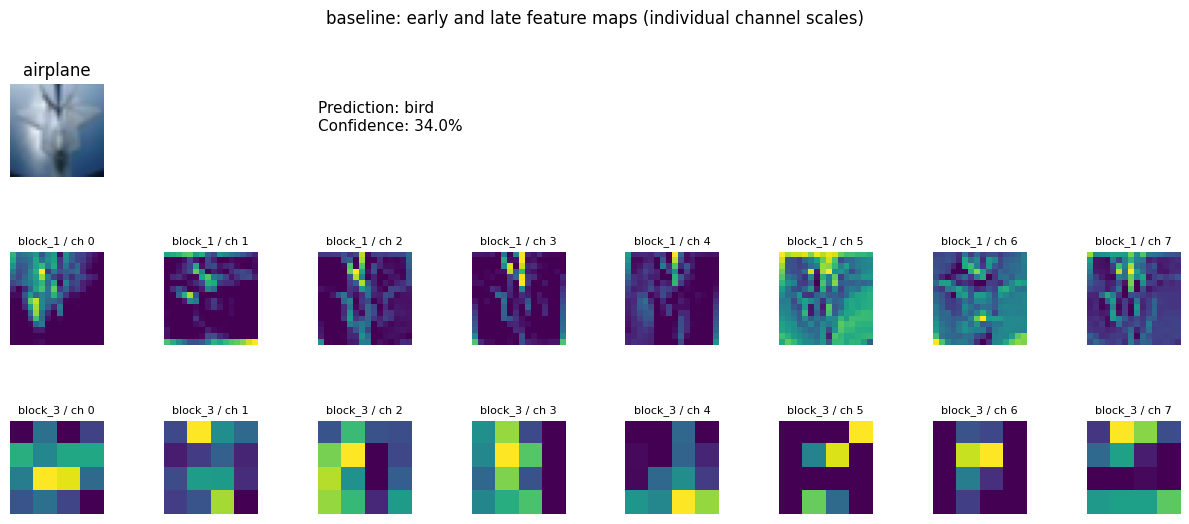

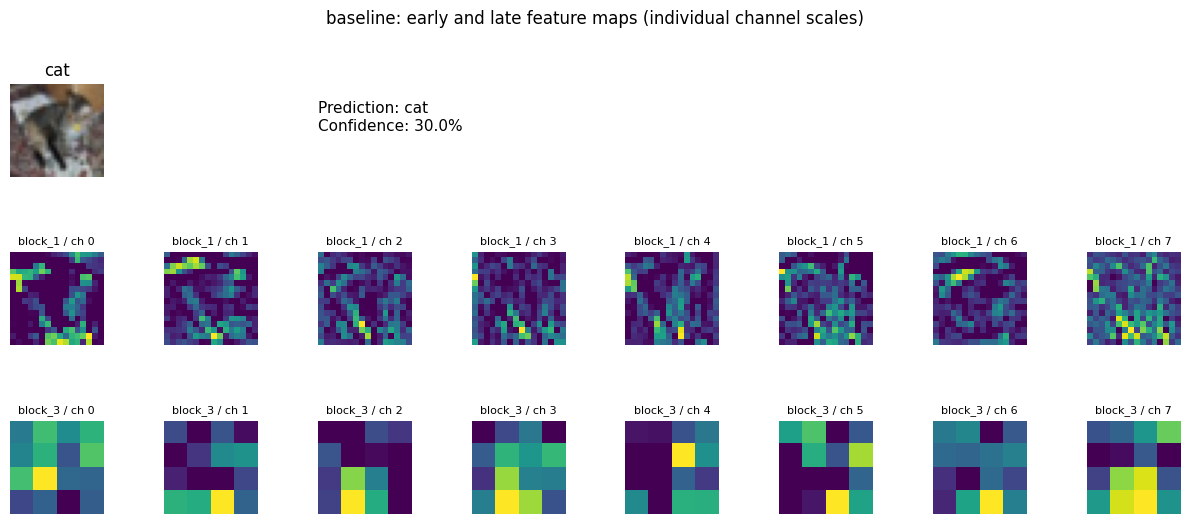

,model,class,block,shape,near_constant_channels
0,baseline,airplane,block_1,"[1, 16, 16, 16]",0
1,baseline,airplane,block_2,"[1, 32, 8, 8]",2
2,baseline,airplane,block_3,"[1, 64, 4, 4]",0
3,baseline,cat,block_1,"[1, 16, 16, 16]",0
4,baseline,cat,block_2,"[1, 32, 8, 8]",0
5,baseline,cat,block_3,"[1, 64, 4, 4]",0


1029

In [7]:
# Hooks observe post-activation block outputs; no gradients or weight updates are needed.
@torch.inference_mode()
def capture_blocks(model, image):
    activations, handles = {}, []
    def hook_for(name):
        def hook(module, inputs, output):
            activations[name] = output.detach().cpu()
        return hook
    try:
        for i, block in enumerate(model.features):
            handles.append(block.register_forward_hook(hook_for(f"block_{i+1}")))
        model.eval()
        logits = model(image.unsqueeze(0).to(device, memory_format=torch.channels_last))
    finally:
        for handle in handles:
            handle.remove()
    return activations, logits.softmax(1).cpu()[0]

# Choose first validation airplane and first validation cat, independent of predictions.
validation_labels = np.array(raw_train.targets)[val_indices]
feature_examples = [int(np.flatnonzero(validation_labels == label)[0]) for label in (0, 3)]
feature_stats = []
def plot_feature_maps(model, prefix):
    rows = []
    for position in feature_examples:
        image, label = val_dataset[position]
        activations, probabilities = capture_blocks(model, image)
        names = [list(activations)[0], list(activations)[-1]]
        fig, axes = plt.subplots(3, 8, figsize=(12, 5.6))
        axes[0, 0].imshow(denormalize(image.unsqueeze(0))[0].permute(1, 2, 0))
        axes[0, 0].set_title(CLASS_NAMES[label])
        for ax in axes[0]: ax.axis("off")
        axes[0, 2].text(0, .5, f'Prediction: {CLASS_NAMES[int(probabilities.argmax())]}\nConfidence: {float(probabilities.max()):.1%}',
                        transform=axes[0, 2].transAxes, fontsize=11)
        for row, name in enumerate(names, 1):
            values = activations[name][0]
            for channel, ax in enumerate(axes[row]):
                # Separate channel scales reveal spatial patterns; brightness is not comparable across panels.
                ax.imshow(values[channel], cmap="viridis")
                ax.set_title(f"{name} / ch {channel}", fontsize=8); ax.axis("off")
            for name_, value in activations.items():
                if row == 1:
                    rows.append({"model": prefix, "class": CLASS_NAMES[label], "block": name_,
                                 "shape": list(value.shape),
                                 "near_constant_channels": int((value[0].flatten(1).std(1) < 1e-5).sum())})
        fig.suptitle(f"{prefix}: early and late feature maps (individual channel scales)")
        fig.tight_layout(); fig.savefig(FIGURE_DIR / f"{prefix}_features_{CLASS_NAMES[label]}.png", dpi=150)
        plt.show(); plt.close(fig)
    return rows

feature_stats = plot_feature_maps(baseline_model, "baseline")
display(pd.DataFrame(feature_stats))
(RESULT_DIR / "baseline_feature_stats.json").write_text(json.dumps(feature_stats, indent=2))

### Questions 3

1. How do the activation tensor shapes change from the first convolution to the last?
2. Compare early-layer and late-layer feature maps. What differences do you notice?
3. Are all channels visually active? What could an almost-constant activation map indicate?
4. Repeat the inspection with an image from a different class. Do the activations look identical? Why or why not?
5. In your own words, what information is lost when a feature map is downsampled?



### Answers 3
1. Baseline block activations are `(1,16,16,16)`, `(1,32,8,8)`, and
   `(1,64,4,4)` for one image: more channels, less spatial detail.
2. The first block retains finer local boundaries and colour/texture differences.
   The final block is a coarse 4 by 4 spatial summary with a larger receptive field.
   These pictures alone do not identify an individual filter as a specific semantic detector.
3. Channel activity depends on the input. Near-constant channels are counted above
   using spatial standard deviation below `1e-5`; they can mean no matching pattern,
   ReLU suppression, or a nearly uniform response. They do not alone prove a dead filter.
4. Airplane and cat are selected by true validation label, not by attractive activations.
   Their maps differ because they have different input patterns; the same learned filters
   are applied to both. Some responses may still be similar for shared edges/textures.
5. Downsampling discards exact location and fine image details. It saves computation
   and may add local shift tolerance, but small discriminative structures can be lost.
   Each displayed map uses its own intensity scale; cross-panel brightness is not a magnitude comparison.

# Part 4 — Build a configurable CNN

Now design a **general CNN class**. The class must not hard-code a fixed number of convolutional layers. Instead, it must receive an architecture configuration describing the requested sequence of layers.

Your configurable model must support, at minimum:

- A variable number of convolutional layers.
- Per-convolution output channels (number of filters).
- Per-convolution kernel size.
- Per-convolution stride and padding.
- A choice of activation function (at least ReLU and GELU).
- Optional batch normalization after a convolution.
- Optional max pooling after a convolutional block.
- A configurable classifier hidden dimension and dropout.
- A final output dimension of 10 classes.

**Important design challenge:** after an arbitrary sequence of convolution and pooling operations, the spatial dimensions may differ. Use `nn.AdaptiveAvgPool2d((1, 1))` before the classifier so that the classifier input size does not need to be calculated manually.

A configuration is a Python dictionary. The example below is only a starting point. Extend it if you want to support additional layer types such as `Conv2d`, depthwise-separable convolution, or strided convolution blocks.

In [8]:
example_config = {
    "input_channels": 3,
    "num_classes": 10,
    "activation": "relu",
    "conv_blocks": [
        {"out_channels": 32, "kernel_size": 3, "stride": 1, "padding": 1,
         "batch_norm": True, "pool": 2},
        {"out_channels": 64, "kernel_size": 3, "stride": 1, "padding": 1,
         "batch_norm": True, "pool": 2},
        {"out_channels": 128, "kernel_size": 3, "stride": 1, "padding": 1,
         "batch_norm": True, "pool": 2},
    ],
    "classifier_hidden": 128,
    "dropout": 0.3,
}

In [9]:
class ConfigurableCNN(nn.Module):
    """A sequence of standard or depthwise-separable configurable convolution blocks."""
    def __init__(self, config):
        super().__init__()
        self.config = copy.deepcopy(config)
        def activation(name):
            if name == "relu": return nn.ReLU()
            if name == "gelu": return nn.GELU()
            raise ValueError(f"Unsupported activation: {name}")
        blocks = []
        channels = config.get("input_channels", 3)
        default_activation = config.get("activation", "relu")
        if not config["conv_blocks"]:
            raise ValueError("At least one convolution block is required")
        for block in config["conv_blocks"]:
            out = block["out_channels"]
            bn = block.get("batch_norm", False)
            options = {key: block.get(key, default) for key, default in
                       (("kernel_size", 3), ("stride", 1), ("padding", 1))}
            kind = block.get("conv_type", "standard")
            if kind == "standard":
                layers = [nn.Conv2d(channels, out, **options, bias=not bn)]
            elif kind == "depthwise":
                # Depthwise spatial filtering, then a pointwise channel-mixing convolution.
                layers = [nn.Conv2d(channels, channels, **options, groups=channels, bias=False),
                          nn.Conv2d(channels, out, kernel_size=1, bias=not bn)]
            else:
                raise ValueError(f"Unsupported convolution type: {kind}")
            if bn: layers.append(nn.BatchNorm2d(out))
            layers.append(activation(block.get("activation", default_activation)))
            pool = block.get("pool", None)
            if pool:
                pool_type = block.get("pool_type", "max")
                if pool_type not in ("max", "avg"): raise ValueError("pool_type must be max or avg")
                layers.append((nn.MaxPool2d if pool_type == "max" else nn.AvgPool2d)(pool))
            blocks.append(nn.Sequential(*layers))
            channels = out
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        hidden = config.get("classifier_hidden", 64)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(channels, hidden),
                                        activation(default_activation), nn.Dropout(config.get("dropout", 0.0)),
                                        nn.Linear(hidden, config.get("num_classes", 10)))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

# Check the baseline implementation is exactly represented by its configuration.
a, b = BaselineCNN().eval(), ConfigurableCNN(BASELINE_CONFIG).eval()
b.load_state_dict(a.state_dict())
with torch.no_grad():
    probe = torch.randn(2, 3, 32, 32)
    torch.testing.assert_close(a(probe), b(probe), rtol=0, atol=0)
assert parameter_count(a) == parameter_count(b)
# Exercise arbitrary depth, kernels, stride, no BN, GELU, pooling and classifier sizes.
edge_config = {"activation": "gelu", "conv_blocks": [
    {"out_channels": 7, "kernel_size": 5, "stride": 2, "padding": 2, "pool": None},
    {"out_channels": 11, "kernel_size": 3, "stride": 1, "padding": 1,
     "conv_type": "depthwise", "batch_norm": True, "pool": 2}],
    "classifier_hidden": 13, "dropout": 0.2}
with torch.no_grad():
    for config in (BASELINE_CONFIG, example_config, edge_config):
        candidate = ConfigurableCNN(config).eval()
        assert candidate(torch.randn(2, 3, 32, 32)).shape == (2, 10)
        assert candidate(torch.randn(2, 3, 40, 40)).shape == (2, 10)
print("Passed: baseline equivalence; 3 configurations; 32x32 and 40x40 inputs; depthwise and GELU")
del a, b, candidate, probe

Passed: baseline equivalence; 3 configurations; 32x32 and 40x40 inputs; depthwise and GELU


## Part 5 — Architecture optimization experiments

You will now conduct a small, systematic architecture search. You are not expected to find the globally best CIFAR-10 model. You are expected to design meaningful experiments, compare them fairly, and explain what you learned.

Possible choices to explore:

| Design choice | Example values |
|---|---|
| Number of convolution blocks | 2, 3, 4, 5 |
| Filters per block | 16, 32, 64, 128, 256 |
| Kernel size | 3, 5 |
| Convolution type | standard, depthwise-separable |
| Pooling | none, max pool, average pool |
| Batch normalization | on, off |
| Activation | ReLU, GELU |
| Dropout | 0.0, 0.2, 0.4, 0.5 |
| Optimizer | AdamW, SGD with momentum |
| Learning rate | 1e-2, 1e-3, 3e-4 |
| Weight decay | 0, 1e-4, 1e-3 |

### Experiment protocol

- Begin with the same train/validation split and seed.
- Use the same epoch budget for comparisons, unless you explicitly justify a change.
- Change one or two factors at a time. State your hypothesis before running each experiment.
- Record the full configuration, optimizer, learning rate, batch size, epoch count, parameter count, best validation epoch, and metrics.
- Save the training curves for every run.(you are expected to upload them as assignment answers)
- Keep the best model according to a validation metric chosen in advance (for example, validation macro F1 or validation accuracy).
- Only evaluate the selected model on the test set once at the end.

A larger model is not automatically a better model. Consider parameter count, training time, overfitting, and per-class performance.

### Experiment log — complete this table for every run

Add a new row after each run. Include enough detail that another student could reconstruct the model without asking you questions. You may use a spreadsheet or a Python list/dictionary if you prefer.

| Run ID | Hypothesis / change | # conv blocks | Conv types and filters | Kernel / stride / padding | BN / pooling / activation | Dropout | Optimizer / LR / weight decay | Epochs | Parameters | Best val accuracy | Best val loss | Macro F1 (val) | Notes |
|---|---|---:|---|---|---|---:|---|---:|---:|---:|---:|---:|---|
| 01 | Baseline | | | | | | | | | | | | |
| 02 | | | | | | | | | | | | | |
| 03 | | | | | | | | | | | | | |
| 04 | | | | | | | | | | | | | |

**Required:** at least four distinct architecture configurations, including your initial baseline. At least one run must use a different convolution type from standard convolution, once you have implemented it.

## Part 6 — Evaluation metrics: accuracy, precision, recall, and F1

Accuracy alone can hide important errors. For a multiclass classification problem, calculate and report **accuracy, precision, recall, and F1-score**.

### Accuracy

Accuracy is the fraction of all predictions that are correct:

\[
$\text{Accuracy} = \frac{\text{number of correct predictions}}{\text{total number of predictions}}$
\]

It is easy to understand, but it does not explain which classes are being confused. If classes are imbalanced, a model can achieve high accuracy by doing well on common classes while performing poorly on rare classes.

### Precision

For a particular class, precision asks: **of the examples predicted as this class, how many really belong to it?**

\[
$\text{Precision} = \frac{TP}{TP + FP}$
\]

Here, `TP` is true positives and `FP` is false positives for the class being considered. Low precision means the model often assigns that class to examples that actually belong to other classes.

### Recall

For a particular class, recall asks: **of all the examples that really belong to this class, how many did the model find?**

\[
$\text{Recall} = \frac{TP}{TP + FN}$
\]

Here, `FN` is false negatives. Low recall means the model misses many real examples of that class.

### F1-score

F1 is the harmonic mean of precision and recall:

\[
$F1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$
\]

F1 is high only when both precision and recall are reasonably high. It is useful when you want a single score that balances the two.

### Multiclass averaging

For CIFAR-10, precision, recall, and F1 can be calculated separately for each class. We will report:

- **Macro average:** calculate the metric for each of the 10 classes, then take the unweighted mean. Every class contributes equally.
- **Weighted average:** calculate the metric for each class, then average using the number of true examples in each class as weights.
- **Per-class values:** report the individual class results so that strengths and weaknesses are visible.

CIFAR-10 is balanced, so macro and weighted averages may be relatively close, but they answer slightly different questions. Use macro F1 as one of your main model-comparison metrics.

### Questions 4

1. Give an example of a false positive and a false negative for one CIFAR-10 class.
2. Can a model have high precision but low recall for a class? Explain how.
3. Why is macro F1 useful when comparing performance across all 10 classes?
4. What does the confusion matrix tell you that accuracy does not?
5. Which classes are easiest and hardest for your best model? Use the per-class report and confusion matrix as evidence.



## Part 7 — Final model selection and test-set evaluation

Choose your best architecture using validation results. State the selection rule you used (for example, highest validation macro F1, with validation loss as a tie-breaker). Do not select a model based on test-set performance.

Set `best_config` to the configuration you selected, train it using your chosen training procedure, and evaluate the final model on the test set. For a more rigorous final result, you may combine the original training and validation data and train from scratch using the selected hyperparameters, but document that procedure clearly. For this assignment, it is acceptable to use the model trained on the training split and selected using validation results.

## Part 8 — Final report (submit as a PDF file)

Complete the following report in your own words.

### A. Architecture
- Describe your final architecture, including the number and type of convolutional layers.
- List each layer's output channels, kernel size, stride, and padding.
- State where you used batch normalization, activation, pooling, and dropout.
- Report the number of trainable parameters.

### B. Experimentation
- Summarize at least four configurations you tested.
- Explain the hypothesis behind each important change.
- Include training and validation loss/accuracy curves for each run.
- Explain which configuration performed best on validation data and why.
- Discuss at least one experiment that did not improve performance.

### C. Intermediate representations
- Include feature-map visualizations from at least two convolutional layers.
- Explain what you observe in early and deeper layers.
- Discuss how the feature-map dimensions change through the network.

### D. Evaluation
Report the final **test accuracy, macro precision, macro recall, macro F1, weighted precision, weighted recall, and weighted F1**. Include the per-class precision, recall, and F1 report and the confusion matrix.

### E. Reflection
- What was the most influential architecture change?
- Did a deeper or wider network always improve validation performance? Explain.
- Did you observe overfitting? What evidence supports your conclusion?
- If you had another training session, what would you try next?



**Academic integrity:** Your submitted notebook should show your own design decisions, experiments, plots, and explanations. Cite any external code or ideas you adapt.

## Part 9 (optional) : Creative tomfoolery (+20 extra points)
In the context of CNN classification or with the concepts you have learned previously, do something interesting , fun and out of the line.
